# Global Solution - Aprendizado Profundo com Redes Neurais Convolucionais
**Tema:** Segurança pública inteligente em São Paulo - classificação de ocorrências com MLP

**Equipe:**
* Matheus Guedes Grigorio - RM: [568086]
* Vinicius Fernandes Silva Souza - RM: [567977]

---
**Resumo do Dataset:**
A base de dados escolhida foi a de "Veículos Subtraídos" no ano de 2024, disponibilizada pela Secretaria da Segurança Pública do Estado de São Paulo (SSP-SP). Ela contém registros detalhados de ocorrências de roubo e furto de veículos, incluindo dados geográficos (bairro), temporais (período do dia, mês) e características do local e do veículo.
**Fonte:** [Portal de Estatísticas SSP-SP](https://www.ssp.sp.gov.br/estatistica/consultas)
**Arquivo utilizado:** `VeiculosSubtraidos_2024.xlsx`

## 1. Importação e Exploração Inicial

**Objetivo:** Carregar os dados brutos, realizar o recorte geográfico exigido (cidade de São Paulo) e isolar a nossa variável-alvo (target).

**Justificativas Iniciais:**
* **Base Escolhida:** Optamos pela base de veículos subtraídos de 2024 por apresentar um volume de dados robusto e atributos claros e diversificados (bairro, período, tipo de veículo, etc.) que são excelentes indicadores comportamentais para diferenciar a natureza de um roubo (com ameaça) de um furto (sem ameaça).
* **Recorte Geográfico:** Filtramos a coluna `NOME_MUNICIPIO` estritamente para `'S.PAULO'`, garantindo que a análise reflita apenas a realidade da capital paulista.
* **Variável-Alvo:** Utilizamos a coluna `RUBRICA`, mantendo apenas os registros classificados explicitamente como "Roubo (art. 157)" ou "Furto (art. 155)".

In [1]:
import random
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout

import joblib

In [2]:
# 1. Carregando os dados (lendo a aba correta onde os dados estão)
print("Carregando o dataset...")
df_bruto = pd.read_excel('VeiculosSubtraidos_2024.xlsx', sheet_name='VEICULOS_2024')

# 2. Recorte Geográfico (Apenas Capital)
df_sp = df_bruto[df_bruto['NOME_MUNICIPIO'] == 'S.PAULO'].copy()

# 3. Definição do Rótulo (Apenas Roubo e Furto)
# Mapeando os crimes que nos interessam na coluna RUBRICA
crimes_alvo = ['Roubo (art. 157)', 'Furto (art. 155)']
df_sp = df_sp[df_sp['RUBRICA'].isin(crimes_alvo)].copy()

# Visualizando as informações iniciais
print(f"Total de registros após o recorte: {df_sp.shape[0]} linhas e {df_sp.shape[1]} colunas.")
print("\nDistribuição das classes (Target):")
print(df_sp['RUBRICA'].value_counts(normalize=True) * 100)

# Espiando as primeiras linhas
df_sp.head()

Carregando o dataset...
Total de registros após o recorte: 71154 linhas e 56 colunas.

Distribuição das classes (Target):
RUBRICA
Furto (art. 155)    65.31467
Roubo (art. 157)    34.68533
Name: proportion, dtype: float64


,ID_DELEGACIA,NOME_DEPARTAMENTO,NOME_SECCIONAL,NOME_DELEGACIA,NOME_MUNICIPIO,ANO_BO,NUM_BO,VERSAO,CIDADE,NOME_DEPARTAMENTO_CIRC,...,ANO_FABRICACAO,ANO_MODELO,PLACA_VEICULO,DESC_COR_VEICULO,MES,ANO,CMD,BTL,CIA,CD_IBGE
0,10108,DECAP,DEL.SEC.1º CENTRO,08º D.P. BRAS,S.PAULO,2024,AE7772,1,S.PAULO,DECAP,...,2015.0,NaN,FLL3G91,Branco,1,2024,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
1,10108,DECAP,DEL.SEC.1º CENTRO,08º D.P. BRAS,S.PAULO,2024,AE7772,1,S.PAULO,DECAP,...,2015.0,NaN,FLL3G91,Branco,1,2024,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
2,10108,DECAP,DEL.SEC.1º CENTRO,08º D.P. BRAS,S.PAULO,2024,AE7772,1,S.PAULO,DECAP,...,2015.0,NaN,FLL3G91,Branco,1,2024,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
3,10101,DECAP,DEL.SEC.1º CENTRO,01º D.P. SE,S.PAULO,2024,AF7682,1,S.PAULO,DECAP,...,2022.0,2022.0,FXL4B53,Vermelho,1,2024,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308
4,10108,DECAP,DEL.SEC.1º CENTRO,08º D.P. BRAS,S.PAULO,2024,AH0194,3,S.PAULO,DECAP,...,2011.0,2011.0,EUS9727,Cinza,1,2024,CPA/M-1,7ºBPM/M,3ªCIA_4ªCIA,3550308


### 1.5 Análise Exploratória de Dados (EDA)

**Objetivo:** Visualizar a distribuição das nossas features em relação às classes (Roubo vs. Furto) para entender o comportamento dos dados antes de treinar a rede.

**Justificativas Técnicas:**
* A análise exploratória permite-nos validar visualmente se as features escolhidas (`DESCR_PERIODO`, `DESCR_TIPO_VEICULO`, `DESCR_TIPOLOCAL`) têm poder preditivo, ou seja, se o seu comportamento varia de forma percetível entre as ocorrências de Roubo e Furto.
* Utilizaremos gráficos de barras empilhadas para observar a proporção de cada tipo de crime dentro das categorias principais.

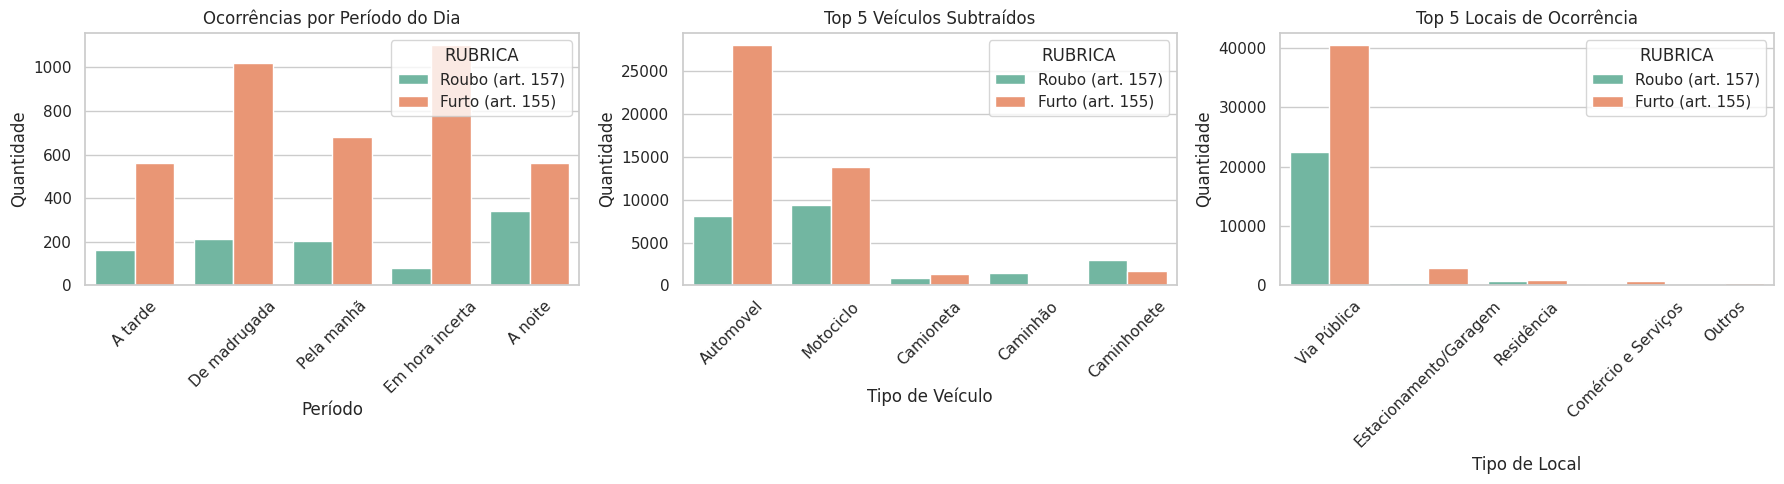

In [4]:
# Configurando o estilo dos gráficos
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Gráfico por Período
sns.countplot(data=df_sp, x='DESCR_PERIODO', hue='RUBRICA', ax=axes[0], palette='Set2')
axes[0].set_title('Ocorrências por Período do Dia')
axes[0].set_xlabel('Período')
axes[0].set_ylabel('Quantidade')
axes[0].tick_params(axis='x', rotation=45)

# 2. Gráfico por Tipo de Veículo (Top 5)
top_veiculos = df_sp['DESCR_TIPO_VEICULO'].value_counts().nlargest(5).index
sns.countplot(data=df_sp[df_sp['DESCR_TIPO_VEICULO'].isin(top_veiculos)],
              x='DESCR_TIPO_VEICULO', hue='RUBRICA', ax=axes[1], palette='Set2')
axes[1].set_title('Top 5 Veículos Subtraídos')
axes[1].set_xlabel('Tipo de Veículo')
axes[1].set_ylabel('Quantidade')
axes[1].tick_params(axis='x', rotation=45)

# 3. Gráfico por Tipo de Local (Top 5)
top_locais = df_sp['DESCR_TIPOLOCAL'].value_counts().nlargest(5).index
sns.countplot(data=df_sp[df_sp['DESCR_TIPOLOCAL'].isin(top_locais)],
              x='DESCR_TIPOLOCAL', hue='RUBRICA', ax=axes[2], palette='Set2')
axes[2].set_title('Top 5 Locais de Ocorrência')
axes[2].set_xlabel('Tipo de Local')
axes[2].set_ylabel('Quantidade')
axes[2].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### Análise dos Resultados Exploratórios

A visualização das features revela padrões comportamentais claros que justificam a sua utilização como entradas (inputs) para a nossa rede neural MLP:

* **Período do Dia:** Existe uma forte correlação temporal com o tipo de crime. O **Roubo** (que envolve grave ameaça ou violência) tem o seu pico "A noite", sugerindo que os criminosos aproveitam a escuridão e o menor movimento para abordar as vítimas. Por outro lado, o **Furto** (subtração sem a presença da vítima) domina nos períodos "De madrugada" e, de forma muito expressiva, "Em hora incerta", o que faz todo o sentido lógico: se a vítima não sabe a que horas o veículo foi levado, é porque não estava presente.
* **Tipo de Veículo:** Automóveis são o alvo preferencial de **Furtos** (provavelmente subtraídos enquanto estão estacionados). Já as Motociclos e Caminhões apresentam uma proporção maior de **Roubos**. No caso dos caminhões, isso pode estar associado a roubos de carga (abordagem em rodovias/vias públicas), enquanto motociclos são frequentemente levados em assaltos no trânsito.
* **Local da Ocorrência:** A esmagadora maioria dos incidentes, independentemente da classe, ocorre em "Via Pública". No entanto, locais como "Residência" e "Estacionamento/Garagem" (onde os veículos estão teoricamente guardados e sem a presença do dono) mostram uma inclinação natural para o **Furto**.

**Conclusão da EDA:** As features escolhidas apresentam variância e poder preditivo suficientes para ajudar a rede neural a traçar a fronteira de decisão entre as duas classes.

---

## 2. Preparação dos Dados: Seleção, Amostragem e Limpeza

**Objetivo:** Reduzir o dataset para o limite exigido, selecionar atributos comportamentais relevantes e tratar valores nulos.

**Justificativas Técnicas:**
* **Dimensionamento e Balanceamento:** O dataset original possui mais de 71 mil linhas, com forte desbalanceamento (65% furto / 35% roubo). Para atender à restrição de tempo do desafio (amostra de 10 a 20 mil) e evitar viés de classe, aplicamos *undersampling*. Selecionamos aleatoriamente 7.500 casos de Roubo e 7.500 casos de Furto, totalizando um dataset perfeitamente balanceado de 15.000 observações.
* **Seleção de Atributos (Features):** Para prever o tipo de crime, descartamos identificadores (como ID, Boletim) e dados de vazamento (a própria classificação). Selecionamos:
    1. `DESCR_PERIODO`: O horário do dia afeta a dinâmica do crime (roubos costumam ocorrer mais à noite/madrugada).
    2. `DESCR_TIPOLOCAL`: O local (via pública, residência, comércio) dita a oportunidade e o contato com a vítima.
    3. `DESCR_TIPO_VEICULO`: O alvo (automóvel vs. motocicleta) altera a abordagem criminosa.
* **Tratamento de Ausentes:** Como nossa amostra é grande, optamos por remover as linhas com valores nulos nas colunas selecionadas (`dropna`), garantindo que a MLP treine apenas com informações completas e fidedignas.

In [5]:
# 1. Selecionando as features que fazem sentido para o modelo + o nosso Target (RUBRICA)
features_selecionadas = ['DESCR_PERIODO', 'DESCR_TIPOLOCAL', 'DESCR_TIPO_VEICULO', 'RUBRICA']
df_modelo = df_sp[features_selecionadas].copy()

# 2. Tratando valores nulos (removendo linhas incompletas)
df_modelo = df_modelo.dropna()

# 3. Dimensionamento e Balanceamento Dinâmico
# Separando as classes após a limpeza de nulos
df_roubo = df_modelo[df_modelo['RUBRICA'] == 'Roubo (art. 157)']
df_furto = df_modelo[df_modelo['RUBRICA'] == 'Furto (art. 155)']

# Descobrimos qual classe tem menos registos válidos e limitamos a 10.000 (para o dataset final ter no máx 20k)
min_amostras = min(df_roubo.shape[0], df_furto.shape[0])
n_amostras = min(min_amostras, 10000)

print(f"Registos válidos após limpeza: {df_roubo.shape[0]} roubos e {df_furto.shape[0]} furtos.")
print(f"Extraindo {n_amostras} amostras de cada classe para balanceamento...")

amostra_roubo = df_roubo.sample(n=n_amostras, random_state=42)
amostra_furto = df_furto.sample(n=n_amostras, random_state=42)

# Juntando e embaralhando o dataset final
df_final = pd.concat([amostra_roubo, amostra_furto]).sample(frac=1, random_state=42).reset_index(drop=True)

print(f"\nTamanho do dataset após balanceamento e limpeza: {df_final.shape[0]} linhas.")
print("Nova distribuição das classes:")
print(df_final['RUBRICA'].value_counts())

Registos válidos após limpeza: 994 roubos e 3926 furtos.
Extraindo 994 amostras de cada classe para balanceamento...

Tamanho do dataset após balanceamento e limpeza: 1988 linhas.
Nova distribuição das classes:
RUBRICA
Furto (art. 155)    994
Roubo (art. 157)    994
Name: count, dtype: int64


## 3. Codificação de Variáveis e Divisão (Splits)

**Objetivo:** Transformar os dados de texto em números para a rede neural e separar os dados para o treinamento seguro.

**Justificativas Técnicas:**
* **Codificação Categórica (One-Hot Encoding):** Redes neurais MLP exigem entradas numéricas. Usamos `pd.get_dummies()` para converter nossas variáveis categóricas (período, local, veículo) em colunas binárias. Isso evita que o modelo atribua pesos ordinais irreais (ex: achar que "Noite" vale mais que "Tarde").
* **Codificação do Target (Label Encoding):** Convertemos a saída para formato binário: `0` para Furto e `1` para Roubo.
* **Divisão Treino/Validação/Teste:**
  * 70% para **Treinamento** (ajuste dos pesos da rede).
  * 15% para **Validação** (monitorar *overfitting* e ajudar a escolher a melhor arquitetura).
  * 15% para **Teste** (isolado até o fim, para avaliar a performance final do modelo escolhido, evitando *data leakage*).

In [6]:
# 1. Separando X (features) e y (target)
X_categorico = df_final.drop(columns=['RUBRICA'])
y_texto = df_final['RUBRICA']

# 2. One-Hot Encoding nas features de entrada
X = pd.get_dummies(X_categorico, drop_first=True)
# Convertendo booleanos para inteiros (0 e 1), caso o pandas gere True/False
X = X.astype(int)

# 3. Label Encoding no Target (Furto = 0, Roubo = 1)
le = LabelEncoder()
y = le.fit_transform(y_texto)

print(f"Mapeamento do Target: {dict(zip(le.classes_, le.transform(le.classes_)))}")
print(f"Quantidade final de features numéricas de entrada na MLP: {X.shape[1]}")

# 4. Divisão Treino, Validação e Teste (70% / 15% / 15%)
# Primeiro, separamos 70% para treino e 30% para um conjunto temporário
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=42, stratify=y)

# Agora dividimos os 30% restantes no meio (15% validação, 15% teste)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp)

print("\nDistribuição dos Splits:")
print(f"Treino: {X_train.shape[0]} amostras")
print(f"Validação: {X_val.shape[0]} amostras")
print(f"Teste: {X_test.shape[0]} amostras")

Mapeamento do Target: {'Furto (art. 155)': np.int64(0), 'Roubo (art. 157)': np.int64(1)}
Quantidade final de features numéricas de entrada na MLP: 31

Distribuição dos Splits:
Treino: 1391 amostras
Validação: 298 amostras
Teste: 299 amostras


## 4. Implementação da MLP e Experimentos com Arquiteturas

**Objetivo:** Construir, treinar e comparar três configurações diferentes de redes neurais Multilayer Perceptron (MLP) utilizando o TensorFlow/Keras para a nossa classificação binária (Roubo vs. Furto).

**Justificativas Técnicas e Arquiteturas:**
Como identificamos 31 features numéricas na etapa de codificação, todas as redes terão uma camada de entrada com essa dimensão. A camada de saída terá sempre 1 neurônio com a função de ativação `sigmoid`, ideal para retornar a probabilidade da classe positiva (Roubo = 1). A função de perda escolhida é a `binary_crossentropy`, e o otimizador é o `Adam` (pela sua eficiência em ajustar a taxa de aprendizagem).

Testaremos as seguintes variações para avaliar o impacto na performance e evitar *overfitting* ou *underfitting*:
*   **Modelo 1 (Base):** Uma arquitetura simples com apenas 1 camada oculta de 16 neurônios (ativação ReLU). Serve como *baseline*.
*   **Modelo 2 (Profunda):** Adicionamos complexidade com 2 camadas ocultas (32 e 16 neurônios). O objetivo é permitir que a rede aprenda relações mais complexas entre os dados.
*   **Modelo 3 (Regularizada):** Mantemos as 2 camadas ocultas (expandidas para 64 e 32 neurônios), mas introduzimos camadas de `Dropout` (taxa de 30%). O *dropout* desliga aleatoriamente neurônios durante o treino, forçando a rede a generalizar melhor e combatendo potenciais sinais de *overfitting* vistos no Modelo 2.

In [7]:
# Fixando sementes para reprodutibilidade dos resultados
tf.random.set_seed(42)
np.random.seed(42)
random.seed(42)

dimensao_entrada = X_train.shape[1] # 31 features

# --- DEFINIÇÃO DOS MODELOS ---

# Modelo 1: Simples (Baseline)
modelo_1 = Sequential([
    Dense(16, activation='relu', input_shape=(dimensao_entrada,)),
    Dense(1, activation='sigmoid')
])
modelo_1.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Modelo 2: Mais Profundo (Maior capacidade de aprendizado)
modelo_2 = Sequential([
    Dense(32, activation='relu', input_shape=(dimensao_entrada,)),
    Dense(16, activation='relu'),
    Dense(1, activation='sigmoid')
])
modelo_2.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Modelo 3: Regularizado com Dropout (Combate ao Overfitting)
modelo_3 = Sequential([
    Dense(64, activation='relu', input_shape=(dimensao_entrada,)),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.3),
    Dense(1, activation='sigmoid')
])
modelo_3.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# --- TREINAMENTO ---

epocas = 30
tamanho_lote = 32

print("Treinando Modelo 1...")
history_1 = modelo_1.fit(X_train, y_train, epochs=epocas, batch_size=tamanho_lote,
                         validation_data=(X_val, y_val), verbose=0)

print("Treinando Modelo 2...")
history_2 = modelo_2.fit(X_train, y_train, epochs=epocas, batch_size=tamanho_lote,
                         validation_data=(X_val, y_val), verbose=0)

print("Treinando Modelo 3...")
history_3 = modelo_3.fit(X_train, y_train, epochs=epocas, batch_size=tamanho_lote,
                         validation_data=(X_val, y_val), verbose=0)

# Avaliação rápida da Acurácia na Validação no final do treino
acc_1 = history_1.history['val_accuracy'][-1]
acc_2 = history_2.history['val_accuracy'][-1]
acc_3 = history_3.history['val_accuracy'][-1]

print(f"Acurácia de Validação - Modelo 1: {acc_1:.4f}")
print(f"Acurácia de Validação - Modelo 2: {acc_2:.4f}")
print(f"Acurácia de Validação - Modelo 3: {acc_3:.4f}")

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Treinando Modelo 1...
Treinando Modelo 2...
Treinando Modelo 3...
Acurácia de Validação - Modelo 1: 0.7215
Acurácia de Validação - Modelo 2: 0.7349
Acurácia de Validação - Modelo 3: 0.7349


## 5. Avaliação, Comparação e Seleção do Modelo

**Objetivo:** Comparar as três arquiteturas testadas utilizando métricas mais robustas que a acurácia (Precision, Recall, F1-Score), analisar as curvas de aprendizagem e escolher o melhor modelo com base no conjunto de Validação, reservando o Teste para o veredito final.

**Justificativas Técnicas:**
* **Métricas de Comparação:** A acurácia isolada pode ser enganosa. Utilizamos o *F1-Score* (que equilibra Precision e Recall) como critério principal, pois é importante tanto não classificar um furto como roubo (Precision) quanto garantir que capturamos a maioria dos roubos reais (Recall).
* **Análise Gráfica:** Traçamos as curvas de Perda (Loss) e Acurácia ao longo das épocas para os conjuntos de Treino e Validação. Isso permite diagnosticar *overfitting* (se a perda de treino continuar caindo enquanto a de validação sobe) ou *underfitting*.
* **Matriz de Confusão:** Será gerada para o modelo campeão, demonstrando visualmente os falsos positivos e falsos negativos.

In [8]:
# Função auxiliar para extrair métricas de validação
def avaliar_modelo(modelo, X_val, y_val):
    y_pred_prob = modelo.predict(X_val, verbose=0)
    y_pred = (y_pred_prob > 0.5).astype(int)

    acc = accuracy_score(y_val, y_pred)
    prec = precision_score(y_val, y_pred)
    rec = recall_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred)
    return acc, prec, rec, f1

# Avaliando os 3 modelos no conjunto de Validação
acc1, prec1, rec1, f1_1 = avaliar_modelo(modelo_1, X_val, y_val)
acc2, prec2, rec2, f1_2 = avaliar_modelo(modelo_2, X_val, y_val)
acc3, prec3, rec3, f1_3 = avaliar_modelo(modelo_3, X_val, y_val)

# Criando a tabela comparativa exigida pelo PDF
resultados = pd.DataFrame({
    'Modelo': ['1 (Simples)', '2 (Profundo)', '3 (Dropout)'],
    'Acurácia': [acc1, acc2, acc3],
    'Precision': [prec1, prec2, prec3],
    'Recall': [rec1, rec2, rec3],
    'F1-Score': [f1_1, f1_2, f1_3]
})

print("--- TABELA COMPARATIVA DE ARQUITETURAS (CONJUNTO DE VALIDAÇÃO) ---")
display(resultados.round(4))

# Selecionando o melhor modelo automaticamente com base no F1-Score
melhor_f1 = resultados['F1-Score'].max()
idx_melhor = resultados['F1-Score'].idxmax()
nome_campeao = resultados.loc[idx_melhor, 'Modelo']

print(f"\nO modelo selecionado foi o Modelo {nome_campeao} por apresentar o melhor equilíbrio de métricas (F1-Score: {melhor_f1:.4f}).")

# Atribuindo variáveis dinamicamente para usar na próxima célula (gráficos)
modelos_dict = {'1 (Simples)': (modelo_1, history_1), '2 (Profundo)': (modelo_2, history_2), '3 (Dropout)': (modelo_3, history_3)}
modelo_campeao, history_campeao = modelos_dict[nome_campeao]

--- TABELA COMPARATIVA DE ARQUITETURAS (CONJUNTO DE VALIDAÇÃO) ---


,Modelo,Acurácia,Precision,Recall,F1-Score
0,1 (Simples),0.7215,0.7037,0.7651,0.7331
1,2 (Profundo),0.7349,0.7397,0.7248,0.7322
2,3 (Dropout),0.7349,0.7397,0.7248,0.7322



O modelo selecionado foi o Modelo 1 (Simples) por apresentar o melhor equilíbrio de métricas (F1-Score: 0.7331).


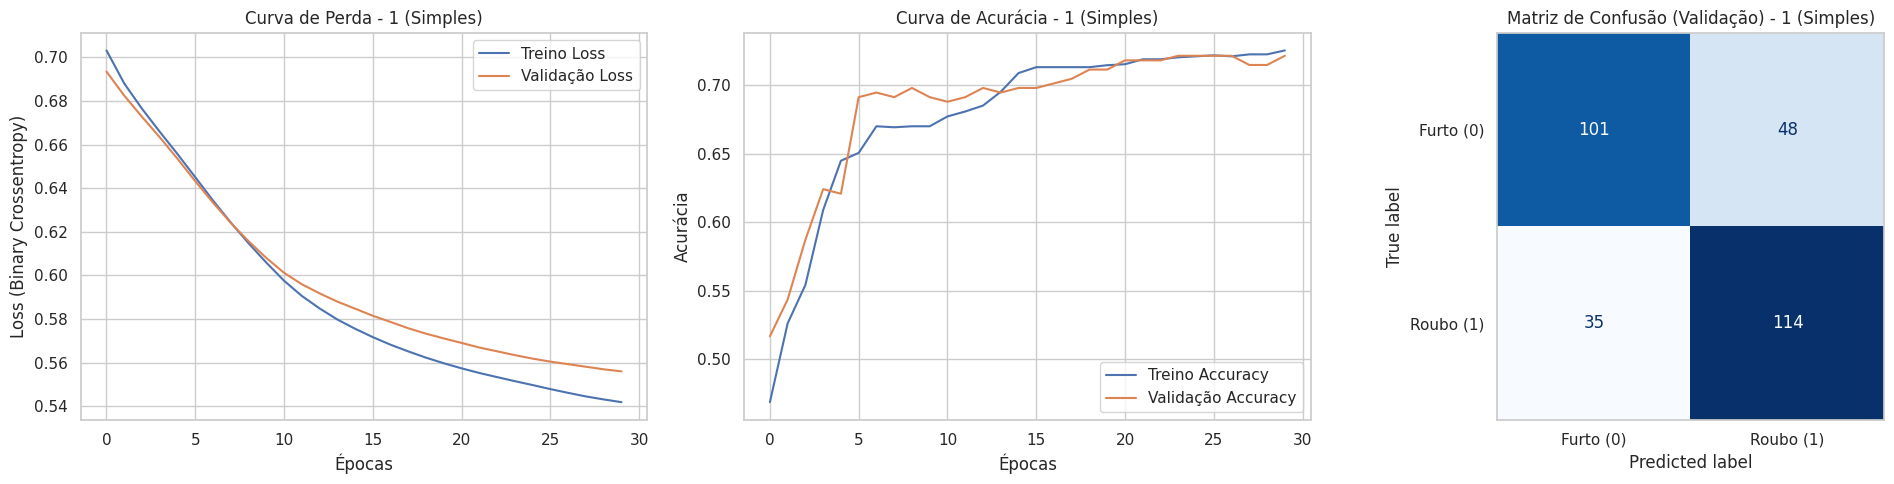


--- AVALIAÇÃO FINAL NO CONJUNTO DE TESTE ---
              precision    recall  f1-score   support

       Furto       0.70      0.72      0.71       150
       Roubo       0.71      0.68      0.70       149

    accuracy                           0.70       299
   macro avg       0.70      0.70      0.70       299
weighted avg       0.70      0.70      0.70       299



In [9]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

# 1. Gráfico de Perda (Loss) do Modelo Campeão
axes[0].plot(history_campeao.history['loss'], label='Treino Loss')
axes[0].plot(history_campeao.history['val_loss'], label='Validação Loss')
axes[0].set_title(f'Curva de Perda - {nome_campeao}')
axes[0].set_xlabel('Épocas')
axes[0].set_ylabel('Loss (Binary Crossentropy)')
axes[0].legend()

# 2. Gráfico de Acurácia do Modelo Campeão
axes[1].plot(history_campeao.history['accuracy'], label='Treino Accuracy')
axes[1].plot(history_campeao.history['val_accuracy'], label='Validação Accuracy')
axes[1].set_title(f'Curva de Acurácia - {nome_campeao}')
axes[1].set_xlabel('Épocas')
axes[1].set_ylabel('Acurácia')
axes[1].legend()

# 3. Matriz de Confusão do Modelo Campeão (no conjunto de Validação)
y_pred_prob_val = modelo_campeao.predict(X_val, verbose=0)
y_pred_val = (y_pred_prob_val > 0.5).astype(int)
cm = confusion_matrix(y_val, y_pred_val)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Furto (0)', 'Roubo (1)'])
disp.plot(ax=axes[2], cmap='Blues', colorbar=False)
axes[2].set_title(f'Matriz de Confusão (Validação) - {nome_campeao}')
axes[2].grid(False)

plt.tight_layout()
plt.show()

# --- AVALIAÇÃO FINAL NO CONJUNTO DE TESTE ---
print("\n--- AVALIAÇÃO FINAL NO CONJUNTO DE TESTE ---")
y_pred_prob_test = modelo_campeao.predict(X_test, verbose=0)
y_pred_test = (y_pred_prob_test > 0.5).astype(int)
print(classification_report(y_test, y_pred_test, target_names=['Furto', 'Roubo']))

###5.1 Curvas de Aprendizado: Comparação das Arquiteturas

**Objetivo:** Visualizar a evolução da Perda (Loss) e da Acurácia durante as 30 épocas de treinamento para as três arquiteturas testadas.

**Justificativa Técnica:**
A análise destas curvas permite-nos diagnosticar o comportamento do modelo durante o treino:
* **Convergência:** Verificar se a rede está efetivamente a aprender (a perda deve diminuir e a acurácia aumentar).
* **Overfitting:** Ocorre se a perda de treino continuar a cair enquanto a perda de validação estabiliza ou começa a subir.
* **Impacto da Regularização:** Observar como o Dropout (Modelo 3) afeta a suavidade das curvas em comparação com a rede profunda sem regularização (Modelo 2).

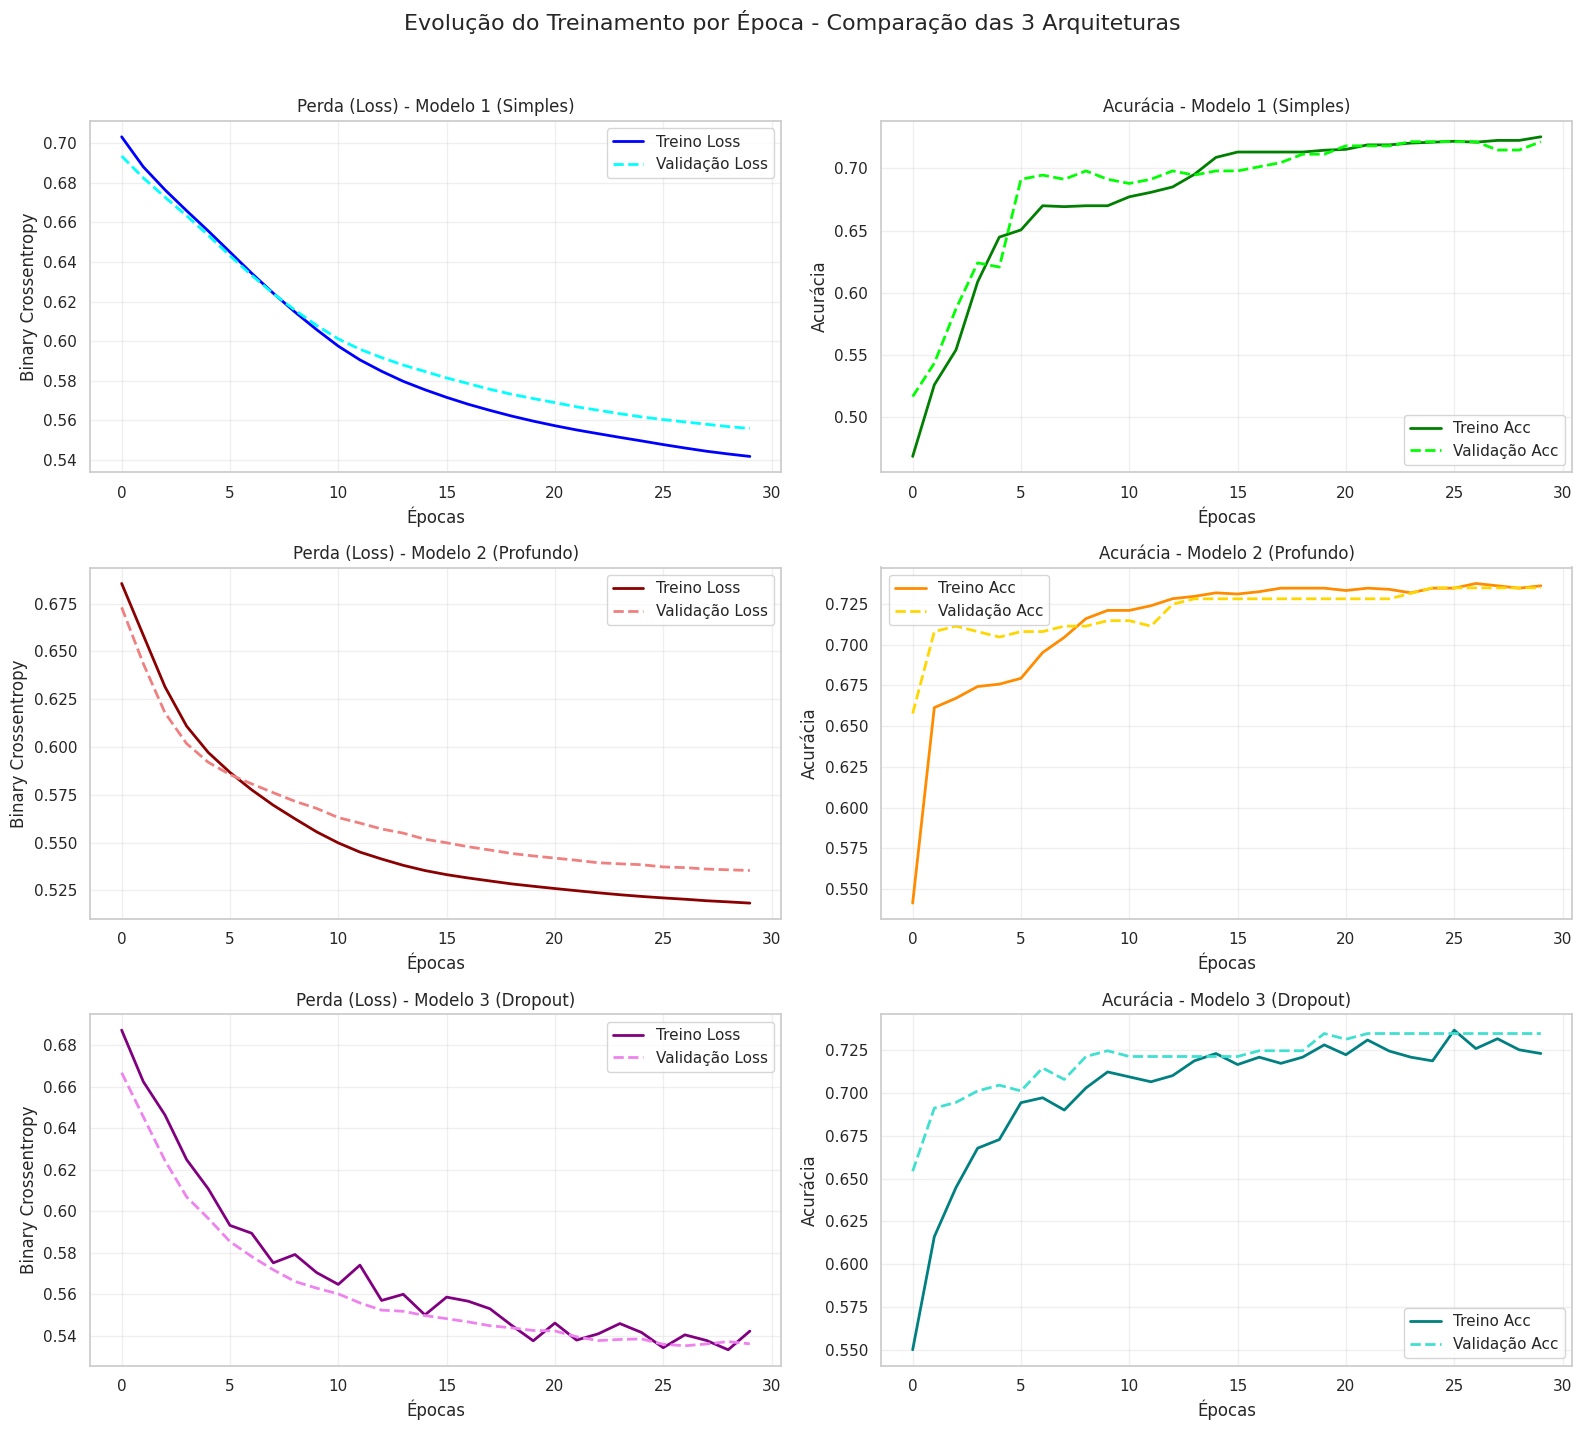

In [10]:
# Criando uma grade de gráficos: 3 linhas (uma para cada modelo) e 2 colunas (Loss e Accuracy)
fig, axes = plt.subplots(3, 2, figsize=(16, 14))
fig.suptitle('Evolução do Treinamento por Época - Comparação das 3 Arquiteturas', fontsize=16, y=1.02)

historicos = [history_1, history_2, history_3]
nomes_modelos = ['Modelo 1 (Simples)', 'Modelo 2 (Profundo)', 'Modelo 3 (Dropout)']
cores_loss = [('blue', 'cyan'), ('darkred', 'lightcoral'), ('purple', 'violet')]
cores_acc = [('green', 'lime'), ('darkorange', 'gold'), ('teal', 'turquoise')]

for i, (hist, nome) in enumerate(zip(historicos, nomes_modelos)):
    # 1. Gráfico de Perda (Loss)
    axes[i, 0].plot(hist.history['loss'], label='Treino Loss', color=cores_loss[i][0], linewidth=2)
    axes[i, 0].plot(hist.history['val_loss'], label='Validação Loss', color=cores_loss[i][1], linewidth=2, linestyle='--')
    axes[i, 0].set_title(f'Perda (Loss) - {nome}')
    axes[i, 0].set_xlabel('Épocas')
    axes[i, 0].set_ylabel('Binary Crossentropy')
    axes[i, 0].legend()
    axes[i, 0].grid(True, alpha=0.3)

    # 2. Gráfico de Acurácia (Accuracy)
    axes[i, 1].plot(hist.history['accuracy'], label='Treino Acc', color=cores_acc[i][0], linewidth=2)
    axes[i, 1].plot(hist.history['val_accuracy'], label='Validação Acc', color=cores_acc[i][1], linewidth=2, linestyle='--')
    axes[i, 1].set_title(f'Acurácia - {nome}')
    axes[i, 1].set_xlabel('Épocas')
    axes[i, 1].set_ylabel('Acurácia')
    axes[i, 1].legend()
    axes[i, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## 6. Exportação do Modelo e Estrutura de Dados

**Objetivo:** Guardar o modelo treinado e a estrutura exata das colunas (após o *One-Hot Encoding*) para que a Aplicação Web possa carregar a rede neural e receber novos dados de utilizadores no formato correto.

**Justificativas Técnicas:**
* Escolhemos o **Modelo 1 (Simples)**. Apesar de a Acurácia global e a Precision serem marginalmente inferiores aos modelos mais profundos, o Modelo 1 obteve o melhor **F1-Score** devido ao seu **Recall** superior. Em cenários de segurança pública (prever Roubo vs. Furto), priorizamos a capacidade do modelo de detetar corretamente ocorrências de Roubo (classe com ameaça/violência), minimizando os falsos negativos.
* Guardamos o modelo no formato `.keras` (ou `.h5`) e utilizamos a biblioteca `joblib` para exportar a lista de colunas de entrada. Isto garante que, na aplicação web, os dados inseridos no formulário sejam convertidos exatamente para as 31 *features* numéricas que a MLP espera.

In [11]:
# 1. Guardar o modelo treinado (Keras)
nome_arquivo_modelo = 'modelo_mlp_seguranca.keras'
modelo_campeao.save(nome_arquivo_modelo)

# 2. Guardar a lista de colunas geradas pelo One-Hot Encoding
# Isso é crucial para a aplicação web saber exatamente quais colunas preencher com 0 ou 1
colunas_entrada = list(X.columns)
joblib.dump(colunas_entrada, 'colunas_entrada.pkl')

print(f"Modelo guardado com sucesso como: {nome_arquivo_modelo}")
print(f"Estrutura de {len(colunas_entrada)} colunas guardada como: colunas_entrada.pkl")

Modelo guardado com sucesso como: modelo_mlp_seguranca.keras
Estrutura de 31 colunas guardada como: colunas_entrada.pkl
